# LightGBM Model

## Setup

Install LightGBM and import the libraries used throughout.

In [1]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silence a harmless joblib warning on Windows

import time
from itertools import product
from pathlib import Path

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


## Configurations

Paths, target column, baseline names and the LightGBM parameter grid.

In [3]:
DATA_DIR = Path("../Feature Selection/Output")   # screened data from feature_selection.ipynb
BASELINE_DIR = Path("../cleaned_data")           # baseline predictions
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "ac_load_kw"
CATEGORICAL = ["zone_code"]          # let LightGBM treat the zone as a category
BASELINES = ["B1 seasonal naive", "B2 average profile", "B3 calendar + AC lags"]
SEED = 42

# Small, fast grid. l1 objective aligns with MAE/WAPE; l2 with RMSE.
PARAM_GRID = {
    "objective": ["regression", "regression_l1"],
    "num_leaves": [31, 63],
    "min_child_samples": [20, 100],
}

PARAM_GRID = {
    "objective": ["regression", "regression_l1"],
    "num_leaves": [31, 63],
    "min_child_samples": [20, 100],
}

BASE_PARAMS = dict(learning_rate=0.05, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
                   lambda_l2=1.0, n_estimators=10_000, random_state=SEED, verbose=-1)

PERM_REPEATS = 5            # shuffles per feature
SHAP_SAMPLE = 5000          # rows used for SHAP (mean |SHAP| is stable on a sample)
CORR_THRESHOLD = 0.90       # report feature pairs with |Spearman r| above this


### Logging helpers

Console output for the long-running steps.

In [4]:
def log(msg=""):
    print(msg, flush=True)


def banner(title):
    log("\n" + "=" * 78)
    log(title)
    log("=" * 78)
    

## Import data

Load the screened model dataset and feature dictionary (from `Feature Selection/Output`)
and the baseline predictions, split into
train / validation / test, and tag each feature with its group (indoor, weather,
AC lag, calendar/zone).

In [5]:
t0 = time.time()
df = pd.read_parquet(DATA_DIR / "question_b_model_data_screened.parquet")
fdict = pd.read_csv(DATA_DIR / "question_b_feature_dictionary_screened.csv")
baselines = pd.read_parquet(BASELINE_DIR / "question_b_baseline_predictions.parquet")

ALL_FEATURES = fdict.loc[fdict["stage1_decision"].eq("keep"), "column"].tolist()   # every screened feature
GROUP = {}
for c in ALL_FEATURES:
    GROUP[c] = ("indoor" if c.startswith("indoor") else
                "weather" if c.startswith(("outdoor", "rainfall", "solar")) else
                "AC lag" if c.startswith("ac_load") else "calendar/zone")

df["zone_code"] = df["zone_code"].astype("category")
train = df[df.split == "train"]
valid = df[df.split == "validation"]
full = df[df.split.isin(["train", "validation"])]
test = df[df.split == "test"]
OP_VALID = valid.is_operating_hours.eq(1).values
log(f"Loaded {len(df):,} rows in {time.time() - t0:.1f}s | train {len(train):,} | "
    f"validation {len(valid):,} | test {len(test):,} | {len(ALL_FEATURES)} screened features")


Loaded 209,119 rows in 0.1s | train 111,779 | validation 46,773 | test 50,567 | 21 screened features


In [6]:
df.head(10)

,zone_id,timestamp,split,is_operating_hours,ac_load_kw,zone_code,hour,weekday,is_holiday,ac_load_kw_yesterday,...,indoor_humidity_pct_last_week,indoor_humidity_pct_yesterday_avg,outdoor_temp_hourly_c,outdoor_temp_daily_avg_c,outdoor_humidity_hourly_pct,outdoor_humidity_daily_avg_pct,rainfall_hourly_mm,rainfall_daily_total_mm,solar_radiation_hourly_wm2,solar_radiation_daily_total_mjm2
0,F2_Z1,2018-07-01 00:00:00,test,0,0.0,0,0,6,0,NaN,...,NaN,NaN,27.1,28.8,88,74,0.0,0.1,0.0,22.76
1,F2_Z1,2018-07-01 01:00:00,test,0,0.0,0,1,6,0,NaN,...,NaN,NaN,26.8,28.8,88,74,0.0,0.1,0.0,22.76
2,F2_Z1,2018-07-01 02:00:00,test,0,0.0,0,2,6,0,NaN,...,NaN,NaN,26.5,28.8,86,74,0.0,0.1,0.0,22.76
3,F2_Z1,2018-07-01 03:00:00,test,0,0.0,0,3,6,0,NaN,...,NaN,NaN,25.9,28.8,84,74,0.0,0.1,0.0,22.76
4,F2_Z1,2018-07-01 04:00:00,test,0,0.0,0,4,6,0,NaN,...,NaN,NaN,25.5,28.8,84,74,0.0,0.1,0.0,22.76
5,F2_Z1,2018-07-01 05:00:00,test,0,0.0,0,5,6,0,NaN,...,NaN,NaN,25.4,28.8,85,74,0.0,0.1,0.0,22.76
6,F2_Z1,2018-07-01 06:00:00,test,0,0.0,0,6,6,0,NaN,...,NaN,NaN,25.1,28.8,86,74,0.0,0.1,70.0,22.76
7,F2_Z1,2018-07-01 07:00:00,test,0,0.0,0,7,6,0,NaN,...,NaN,NaN,26.1,28.8,82,74,0.0,0.1,261.0,22.76
8,F2_Z1,2018-07-01 08:00:00,test,0,0.0,0,8,6,0,NaN,...,NaN,NaN,27.8,28.8,74,74,0.0,0.1,462.0,22.76
9,F2_Z1,2018-07-01 09:00:00,test,0,0.0,0,9,6,0,NaN,...,NaN,NaN,29.3,28.8,67,74,0.0,0.1,626.0,22.76


## Helper functions

Metrics (MAE, RMSE, CV(RMSE), NMBE, WAPE), model fitting with early stopping,
and the grid-search tuner.

In [7]:
def metrics(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    err = y - yhat
    ybar = y.mean()
    rmse = np.sqrt(np.mean(err ** 2))
    return {"n": len(y), "MAE": np.mean(np.abs(err)), "RMSE": rmse,
            "CV(RMSE)%": 100 * rmse / ybar,
            "NMBE%": 100 * err.sum() / (len(y) * ybar),       # +ve = under-predicts
            "WAPE%": 100 * np.abs(err).sum() / np.abs(y).sum()}


def wape(y, yhat):
    return 100 * np.abs(np.asarray(y) - yhat).sum() / np.abs(np.asarray(y)).sum()


def progress_callback(every, label):
    start = time.time()

    def _cb(env):
        i, n = env.iteration + 1, env.end_iteration
        if i % every == 0 or i == n:
            el = time.time() - start
            log(f"    [{label}] tree {i:>5}/{n} ({100 * i / n:5.1f}%) | "
                f"elapsed {el:6.1f}s | ETA {el / i * (n - i):6.1f}s")
    _cb.order = 30
    return _cb


def fit(params, X, y, X_val=None, y_val=None, n_estimators=None, callbacks=None):
    p = {**BASE_PARAMS, **params}
    if n_estimators:
        p["n_estimators"] = n_estimators
    model = lgb.LGBMRegressor(**p)
    kw = {"categorical_feature": [c for c in CATEGORICAL if c in X.columns],
          "callbacks": list(callbacks or [])}
    if X_val is not None:
        kw.update(eval_set=[(X_val, y_val)], eval_metric="l1")
        kw["callbacks"].append(lgb.early_stopping(200, verbose=False))
    model.fit(X, y, **kw)
    return model


def predict(model, X):
    return np.clip(model.predict(X), 0, None)


def tune(features, label):
    """Grid search on train -> validation; returns best params + best iteration."""
    rows = []
    combos = list(product(*PARAM_GRID.values()))
    for i, values in enumerate(combos, 1):
        params = dict(zip(PARAM_GRID, values))
        t = time.time()
        model = fit(params, train[features], train[TARGET], valid[features], valid[TARGET])
        pred = predict(model, valid[features])
        r = {**params, "best_iter": model.best_iteration_,
             "val_WAPE_all%": wape(valid[TARGET], pred),
             "val_WAPE_op%": wape(valid[TARGET][OP_VALID], pred[OP_VALID])}
        rows.append(r)
        log(f"  [{label} {i}/{len(combos)}] {params} iter={r['best_iter']:>4} | "
            f"val WAPE all {r['val_WAPE_all%']:.2f}% op {r['val_WAPE_op%']:.2f}% | {time.time() - t:.0f}s")
    res = pd.DataFrame(rows).sort_values("val_WAPE_op%")
    best = res.iloc[0].to_dict()
    log(f"  -> best {label}: {({k: best[k] for k in PARAM_GRID})} iter={int(best['best_iter'])} "
        f"val WAPE op {best['val_WAPE_op%']:.2f}%")
    return res, best


def as_params(best):
    return {"objective": best["objective"], "num_leaves": int(best["num_leaves"]),
            "min_child_samples": int(best["min_child_samples"])}


## 1. Full Model

Tune and fit LightGBM on all screened features: calendar + AC lags + indoor +
weather. Its validation WAPE on operating hours is the reference the feature
importance is measured against.

In [8]:
banner(f"STEP 1/3  Tune the full model ({len(ALL_FEATURES)} features: calendar + AC lags + indoor + weather)")
tune_full, best_full = tune(ALL_FEATURES, "full")
tune_full.to_csv(OUT_DIR / "tuning_full.csv", index=False)
params = as_params(best_full)
model_full = fit(params, train[ALL_FEATURES], train[TARGET], n_estimators=int(best_full["best_iter"]))
base_pred = predict(model_full, valid[ALL_FEATURES])
base_op = wape(valid[TARGET][OP_VALID], base_pred[OP_VALID])
log(f"  Full model refit on train: val WAPE op-hours {base_op:.2f}%")


STEP 1/3  Tune the full model (21 features: calendar + AC lags + indoor + weather)


C:\Users\zheng\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [full 1/8] {'objective': 'regression', 'num_leaves': 31, 'min_child_samples': 20} iter= 393 | val WAPE all 21.52% op 13.00% | 2s


C:\Users\zheng\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [full 2/8] {'objective': 'regression', 'num_leaves': 31, 'min_child_samples': 100} iter= 321 | val WAPE all 22.20% op 13.17% | 2s


C:\Users\zheng\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (9 outputs left out)

C:\Users\zheng\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [full 8/8] {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100} iter=3719 | val WAPE all 20.20% op 12.83% | 25s


  -> best full: {'objective': 'regression_l1', 'num_leaves': 31, 'min_child_samples': 100} iter=8959 val WAPE op 12.71%


  Full model refit on train: val WAPE op-hours 12.71%


## 2. Feature Comparison

Four views of what each feature is worth: gain, mean |SHAP|, repeated
permutation importance, and Spearman correlation between features. The
permutation test is then repeated per group. All features are kept.

In [9]:
banner("STEP 2/3  Feature comparison on VALIDATION (gain, SHAP, permutation, correlation)")

# 2a. gain
gain = pd.Series(model_full.booster_.feature_importance("gain"), index=ALL_FEATURES)
gain = 100 * gain / gain.sum()
log("  [a] gain importance done")

# 2b. SHAP on a sample of validation rows
t = time.time()
shap_X = valid[ALL_FEATURES].sample(n=min(SHAP_SAMPLE, len(valid)), random_state=SEED)
shap_vals = model_full.predict(shap_X, pred_contrib=True)[:, :-1]
mean_shap = pd.Series(np.abs(shap_vals).mean(axis=0), index=ALL_FEATURES)
log(f"  [b] SHAP on {len(shap_X):,} validation rows done in {time.time() - t:.1f}s")

# 2c. permutation importance (operating-hours WAPE), repeated to measure noise
rng = np.random.default_rng(SEED)
Xv = valid[ALL_FEATURES].copy()
yv_op = valid[TARGET].values[OP_VALID]
perm = {}
t = time.time()
for i, c in enumerate(ALL_FEATURES, 1):
    original = Xv[c].copy()
    scores = []
    for _ in range(PERM_REPEATS):
        Xv[c] = original.values[rng.permutation(len(Xv))]
        if c in CATEGORICAL:
            Xv[c] = Xv[c].astype(original.dtype)
        scores.append(wape(yv_op, predict(model_full, Xv)[OP_VALID]) - base_op)
    Xv[c] = original
    perm[c] = scores
    el = time.time() - t
    log(f"  [c] permutation {i:>2}/{len(ALL_FEATURES)} {c:<36} "
        f"+{np.mean(scores):6.2f} pp (sd {np.std(scores):.2f}) | ETA {el / i * (len(ALL_FEATURES) - i):5.0f}s")

# 2d. correlation between numeric features
corr = valid[[c for c in ALL_FEATURES if c not in CATEGORICAL]].corr(method="spearman")
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > CORR_THRESHOLD]
log(f"  [d] {len(pairs)} feature pairs with |Spearman r| > {CORR_THRESHOLD}")

comp = pd.DataFrame({
    "group": pd.Series(GROUP),
    "gain_%": gain,
    "mean_abs_shap_kW": mean_shap,
    "perm_WAPE_increase_pp": {c: np.mean(v) for c, v in perm.items()},
    "perm_sd_pp": {c: np.std(v) for c, v in perm.items()},
}).loc[ALL_FEATURES]
comp["noise_ratio"] = comp.perm_WAPE_increase_pp / comp.perm_sd_pp.replace(0, np.nan)
comp["rank_perm"] = comp.perm_WAPE_increase_pp.rank(ascending=False).astype(int)
comp["rank_shap"] = comp.mean_abs_shap_kW.rank(ascending=False).astype(int)


STEP 2/3  Feature comparison on VALIDATION (gain, SHAP, permutation, correlation)


  [a] gain importance done


  [b] SHAP on 5,000 validation rows done in 172.3s


  [c] permutation  1/21 zone_code                            +  5.11 pp (sd 0.06) | ETA  1979s


  [c] permutation  2/21 hour                                 +  5.84 pp (sd 0.06) | ETA  1879s


  [c] permutation  3/21 weekday                              + 17.09 pp (sd 0.20) | ETA  1782s


... (15 outputs left out)

  [c] permutation 19/21 rainfall_daily_total_mm              +  0.12 pp (sd 0.02) | ETA   133s


  [c] permutation 20/21 solar_radiation_hourly_wm2           +  6.54 pp (sd 0.07) | ETA    66s


  [c] permutation 21/21 solar_radiation_daily_total_mjm2     +  0.10 pp (sd 0.01) | ETA     0s


  [d] 0 feature pairs with |Spearman r| > 0.9


In [10]:
comp = comp.sort_values("perm_WAPE_increase_pp", ascending=False)
comp.to_csv(OUT_DIR / "feature_comparison.csv")
pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman_r"]).to_csv(
    OUT_DIR / "correlated_pairs.csv", index=False)


In [11]:
group_perm = {}

for g in ["indoor", "weather", "AC lag", "calendar/zone"]:
    cols = [c for c in ALL_FEATURES if GROUP[c] == g]
    Xg = valid[ALL_FEATURES].copy()
    scores = []
    for _ in range(PERM_REPEATS):
        idx = rng.permutation(len(Xg))
        for c in cols:
            Xg[c] = valid[c].values[idx]
            if c in CATEGORICAL:
                Xg[c] = Xg[c].astype(valid[c].dtype)
        scores.append(wape(yv_op, predict(model_full, Xg)[OP_VALID]) - base_op)
    group_perm[g] = (np.mean(scores), np.std(scores), len(cols))

group_tab = pd.DataFrame(group_perm, index=["perm_WAPE_increase_pp", "sd_pp", "n_features"]).T
group_tab.to_csv(OUT_DIR / "feature_group_importance.csv")


### Present the feature comparison

Table and bar chart of permutation importance by feature, coloured by group.

In [12]:
%matplotlib inline

,Group,SHAP kW,Perm +pp,Perm sd
ac_load_kw_last_week,AC lag,3.47,19.69,0.13
weekday,calendar/zone,1.24,17.09,0.20
ac_load_kw_yesterday,AC lag,1.23,15.58,0.11
solar_radiation_hourly_wm2,weather,0.79,6.54,0.07
is_holiday,calendar/zone,0.55,6.53,0.18
hour,calendar/zone,0.37,5.84,0.06
zone_code,calendar/zone,0.34,5.11,0.06
indoor_temp_c_last_week,indoor,0.11,1.24,0.05
outdoor_temp_daily_avg_c,weather,0.13,1.14,0.03
indoor_temp_c_yesterday_avg,indoor,0.09,0.86,0.02


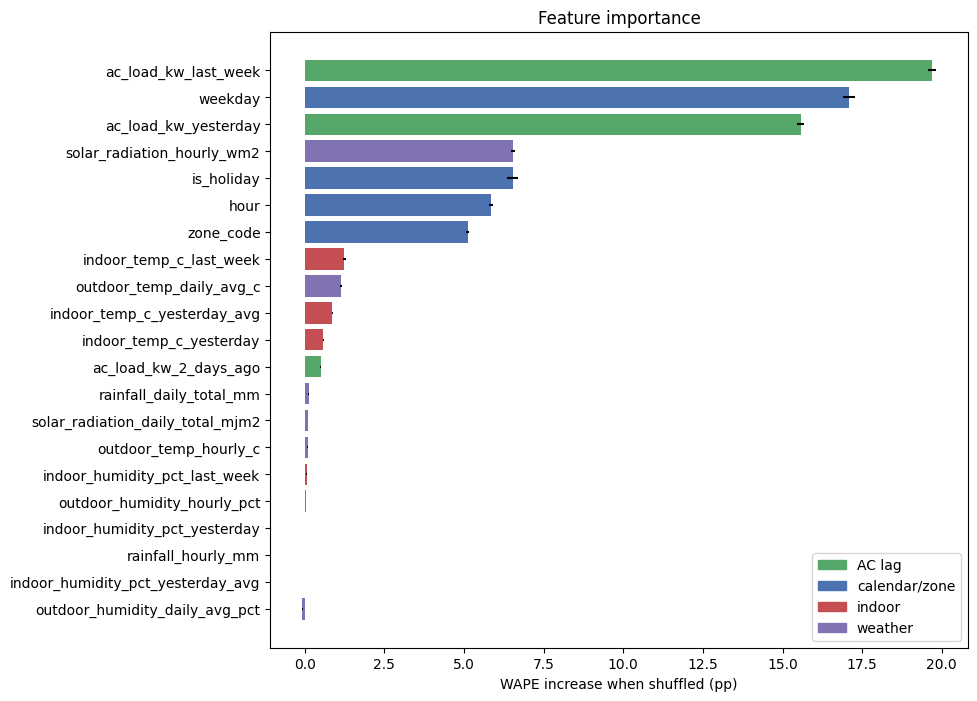

In [13]:
table = pd.DataFrame({
    "Group": comp["group"],
    "SHAP kW": comp["mean_abs_shap_kW"],
    "Perm +pp": comp["perm_WAPE_increase_pp"],
    "Perm sd": comp["perm_sd_pp"],
}).round(2)
display(table)

colors = {"AC lag": "#55A868", "calendar/zone": "#4C72B0", "indoor": "#C44E52", "weather": "#8172B2"}
t = table.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(t.index, t["Perm +pp"], xerr=t["Perm sd"], color=t["Group"].map(colors))
ax.set(xlabel="WAPE increase when shuffled (pp)", title="Feature importance")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], colors, loc="lower right")
fig.savefig(OUT_DIR / "feature_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Build Final Model

Retrain on train + validation (all of 2019) using all screened features and
predict the held-out 2018 test window.

In [14]:
banner(f"STEP 3/3  Retrain final model ({len(ALL_FEATURES)} features) on all 2019, test on Jul-Sep 2018")
FINAL_FEATURES, best_final = ALL_FEATURES, best_full
test_pred = test[["zone_id", "timestamp", "rainfall_hourly_mm"]].copy()
final_models = {}
name = "LGBM final"
n_iter = int(best_final["best_iter"] * len(full) / len(train))
log(f"  {name}: {len(FINAL_FEATURES)} features, {n_iter} trees, {as_params(best_final)}")
t = time.time()
m = fit(as_params(best_final), full[FINAL_FEATURES], full[TARGET], n_estimators=n_iter,
        callbacks=[progress_callback(max(50, n_iter // 5), name)])
test_pred[name] = predict(m, test[FINAL_FEATURES])
final_models[name] = m
log(f"  -> trained + predicted in {time.time() - t:.1f}s")

final_models["LGBM final"].booster_.save_model(str(OUT_DIR / "lgbm_final.txt"))
pd.Series(FINAL_FEATURES, name="feature").to_csv(OUT_DIR / "final_features.csv", index=False)


STEP 3/3  Retrain final model (21 features) on all 2019, test on Jul-Sep 2018


  LGBM final: 21 features, 12707 trees, {'objective': 'regression_l1', 'num_leaves': 31, 'min_child_samples': 100}


    [LGBM final] tree  2541/12707 ( 20.0%) | elapsed   13.0s | ETA   51.9s


    [LGBM final] tree  5082/12707 ( 40.0%) | elapsed   26.7s | ETA   40.1s


    [LGBM final] tree  7623/12707 ( 60.0%) | elapsed   39.3s | ETA   26.2s


    [LGBM final] tree 10164/12707 ( 80.0%) | elapsed   51.2s | ETA   12.8s


    [LGBM final] tree 12705/12707 (100.0%) | elapsed   63.8s | ETA    0.0s


    [LGBM final] tree 12707/12707 (100.0%) | elapsed   63.8s | ETA    0.0s


  -> trained + predicted in 84.8s


## Test

Score the predictions against the baselines on the out-of-year test period
(Jul-Sep 2018): headline metrics, rain vs dry, and a Diebold-Mariano test for
significance.

In [15]:
MODEL_COLS = ["LGBM final"]
cmp = (baselines[baselines.period == "test"]
       .merge(test_pred, on=["zone_id", "timestamp"], how="left"))
cmp = cmp[cmp.scored == 1].copy()
assert cmp[BASELINES + MODEL_COLS].notna().all().all(), "missing predictions on scored rows"
cmp.to_parquet(OUT_DIR / "test_predictions.parquet", index=False)


In [16]:
rows = []
for hours, mask in [("all hours", np.ones(len(cmp), bool)),
                    ("operating hours", cmp.is_operating_hours.eq(1).values)]:
    for c in BASELINES + MODEL_COLS:
        rows.append({"hours": hours, "model": c, **metrics(cmp.loc[mask, TARGET], cmp.loc[mask, c])})
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "test_metrics.csv", index=False)


In [17]:
op = cmp[cmp.is_operating_hours.eq(1)]
rain = pd.DataFrame([{"condition": n, "model": c, "WAPE%": wape(s[TARGET], s[c])}
                     for n, s in [("dry", op[op.rainfall_hourly_mm.eq(0)]),
                                  ("rain", op[op.rainfall_hourly_mm.gt(0)])]
                     for c in BASELINES + MODEL_COLS]).pivot(index="model", columns="condition", values="WAPE%")
rain.to_csv(OUT_DIR / "test_rain_vs_dry.csv")


In [18]:
def diebold_mariano(frame, a, b, max_lag=24):
    """DM on absolute error, averaged across zones per hour; Newey-West variance.
    DM < 0 => model a is more accurate than b."""
    d = (np.abs(frame[TARGET] - frame[a]) - np.abs(frame[TARGET] - frame[b]))
    d = d.groupby(frame.timestamp).mean().sort_index().values
    n, dbar = len(d), d.mean()
    dc = d - dbar
    lrv = dc @ dc / n
    for k in range(1, max_lag + 1):
        lrv += 2 * (1 - k / (max_lag + 1)) * (dc[k:] @ dc[:-k]) / n
    dm = dbar / np.sqrt(lrv / n)
    return dm, 2 * stats.norm.sf(abs(dm))
    

In [19]:
dm_rows = []
for hours, frame in [("all hours", cmp), ("operating hours", op)]:
    for b in BASELINES:
        dm, p = diebold_mariano(frame, "LGBM final", b)
        dm_rows.append({"hours": hours, "model": "LGBM final", "vs": b, "DM": dm, "p_value": p})
dm_tab = pd.DataFrame(dm_rows)
dm_tab.to_csv(OUT_DIR / "test_diebold_mariano.csv", index=False)


## Results (Using WAPE%)

Printed summary and WAPE bar charts for all hours and operating hours.

In [20]:
banner("RESULTS (test = Jul-Sep 2018, scored rows)")
log(results.to_string(index=False))
log("\nRain vs dry (operating hours, WAPE%):")
log(rain.to_string())
log("\nDiebold-Mariano (DM < 0 => LGBM final more accurate):")
log(dm_tab.to_string(index=False))
log(f"\nDone in {(time.time() - t0) / 60:.1f} min. Outputs in {OUT_DIR.resolve()}")


RESULTS (test = Jul-Sep 2018, scored rows)


          hours                 model     n      MAE     RMSE  CV(RMSE)%      NMBE%     WAPE%
      all hours     B1 seasonal naive 46064 1.197930 4.151608  98.179932  -1.270936 28.329428
      all hours    B2 average profile 46064 1.146502 3.002205  70.998098  -7.763172 27.113222
      all hours B3 calendar + AC lags 46064 1.673616 3.402832  80.472406 -12.111553 39.578769
      all hours            LGBM final 46064 0.825846 2.751305  65.064671   2.066162 19.530158
operating hours     B1 seasonal naive 12602 2.313099 4.768478  34.872136   4.700967 16.915814
operating hours    B2 average profile 12602 2.661834 3.846530  28.129883 -11.834572 19.466136
operating hours B3 calendar + AC lags 12602 2.478267 4.022169  29.414334   4.067092 18.123696
operating hours            LGBM final 12602 1.699895 2.781168  20.338831  -0.506664 12.431422



Rain vs dry (operating hours, WAPE%):


condition                    dry       rain
model                                      
B1 seasonal naive      15.483016  18.048679
B2 average profile     20.798047  18.413039
B3 calendar + AC lags  17.022389  18.994462
LGBM final             11.904425  12.848101



Diebold-Mariano (DM < 0 => LGBM final more accurate):


          hours      model                    vs         DM      p_value
      all hours LGBM final     B1 seasonal naive  -3.017082 2.552210e-03
      all hours LGBM final    B2 average profile  -6.790313 1.118902e-11
      all hours LGBM final B3 calendar + AC lags -13.747116 5.300022e-43
operating hours LGBM final     B1 seasonal naive  -1.827200 6.766972e-02
operating hours LGBM final    B2 average profile  -6.351818 2.127845e-10
operating hours LGBM final B3 calendar + AC lags  -5.082777 3.719563e-07



Done in 34.0 min. Outputs in C:\Users\zheng\OneDrive\Documents\SMU (Y3S1)\IS4001 Smart Building Analytics\3. Final Project\Repo\Qn_B\3-LightGBM\outputs


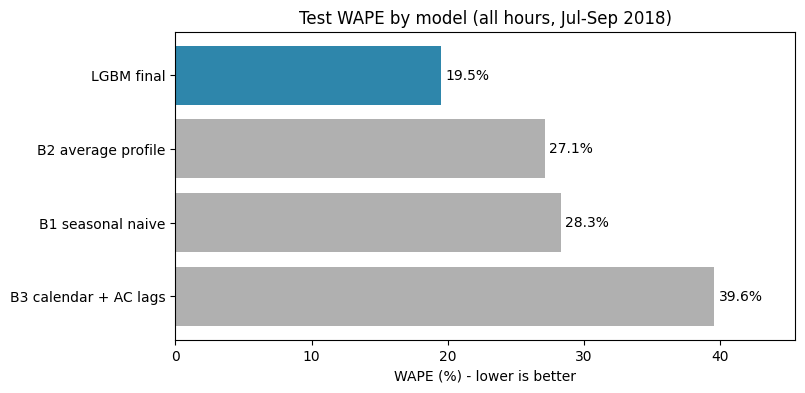

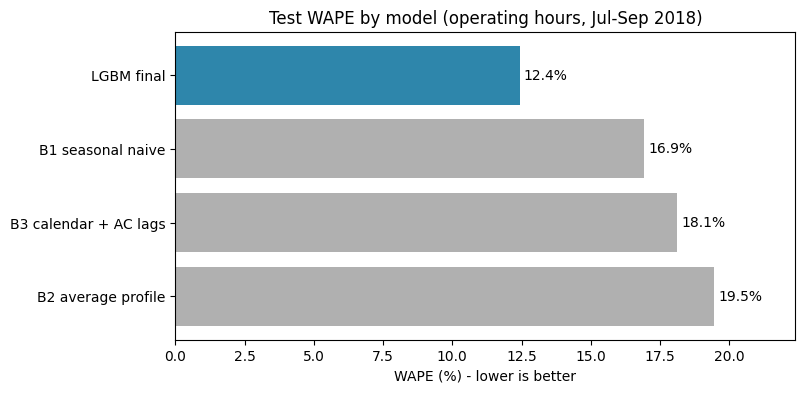

In [21]:
for hours in ["all hours", "operating hours"]:
    r = results[results.hours == hours].sort_values("WAPE%", ascending=False)
    colors = ["#2E86AB" if m.startswith("LGBM") else "#B0B0B0" for m in r.model]
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.barh(r.model, r["WAPE%"], color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set(xlabel="WAPE (%) - lower is better", title=f"Test WAPE by model ({hours}, Jul-Sep 2018)")
    ax.set_xlim(0, r["WAPE%"].max() * 1.15)
    fig.savefig(OUT_DIR / f"wape_{hours.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    try:
        display(fig)          # Jupyter / Colab
    except NameError:
        pass                  # plain script: chart is saved only
    plt.close(fig)


## Export final model as wrapper

Export the final LGBM model as a reusable wrapper (for the web app)

In [22]:
from ac_forecaster import ACLoadForecaster# E

op_test = results[(results.hours == "operating hours") & (results.model == "LGBM final")].iloc[0]
forecaster = ACLoadForecaster.from_model(
    final_models["LGBM final"], FINAL_FEATURES, df,
    metadata={"target": TARGET, "trained_on": "2019 (train + validation)", "params": as_params(best_final),
              "test_WAPE_op%": round(float(op_test["WAPE%"]), 2), "test_CVRMSE_op%": round(float(op_test["CV(RMSE)%"]), 2)})
log(f"Saved {forecaster} to {forecaster.save(OUT_DIR / 'ac_forecaster')}")

Saved ACLoadForecaster(21 features, 23 zones, 12707 trees) to outputs\ac_forecaster
